#### EDA

In [119]:
import pandas as pd

df = pd.read_csv("data/challenge1_train.csv")


In [120]:
df

,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC
...,...,...,...,...,...,...,...,...,...,...
7393,9858,8345,4.0,8,4900,43.0724,-89.4003,housing/rent/apartment,Thumbnail,WI
7394,9860,3200,5.0,6,5199,33.4072,-84.4523,housing/rent/apartment,Thumbnail,GA
7395,9861,4500,5.0,4,5407,44.8653,-93.4749,housing/rent/apartment,Thumbnail,MN
7396,9862,6900,5.0,5,5700,28.1253,-82.4468,housing/rent/apartment,Thumbnail,FL


In [121]:
df["state"].unique()

<StringArray>
['WA', 'NY', 'CA', 'NC', 'TX', 'GA', 'FL', 'MD', 'CO', 'VA', 'NM', 'IL', 'MA',
 'NJ', 'OR', 'DE', 'PA', 'AZ', 'SC', 'MN', 'TN', 'MI', 'KY', 'DC', 'AK', 'IA',
 'CT', 'WI', 'IN', 'NV', 'UT', 'OH', 'MO', 'OK', 'RI', 'NH', 'NE', 'ND', 'AL',
 'AR', 'LA', 'KS', 'ID', 'HI', 'MT', 'VT', 'SD', 'MS', 'ME', 'WV']
Length: 50, dtype: str

In [122]:
df["category"].unique()

<StringArray>
['housing/rent/apartment', 'housing/rent/home', 'housing/rent/short_term']
Length: 3, dtype: str

In [123]:
df["has_photo"].unique()

<StringArray>
['Thumbnail', 'Yes', 'No']
Length: 3, dtype: str

In [124]:
print("Number of training columns:", len(df.columns))

Number of training columns: 10


In [125]:
print(df.columns)

Index(['ID', 'price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude',
       'longitude', 'category', 'has_photo', 'state'],
      dtype='str')


#### Drop price and ID

In [126]:

import pandas as pd

# Load the training dataset
train_df = df.copy()

# Separate target and predictors
y = train_df["price"]
X = train_df.drop(columns=["ID", "price"])

# Check the data
print("Training features:", X.shape)
print("Target:", y.shape)

train_df

Training features: (7398, 8)
Target: (7398,)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC
...,...,...,...,...,...,...,...,...,...,...
7393,9858,8345,4.0,8,4900,43.0724,-89.4003,housing/rent/apartment,Thumbnail,WI
7394,9860,3200,5.0,6,5199,33.4072,-84.4523,housing/rent/apartment,Thumbnail,GA
7395,9861,4500,5.0,4,5407,44.8653,-93.4749,housing/rent/apartment,Thumbnail,MN
7396,9862,6900,5.0,5,5700,28.1253,-82.4468,housing/rent/apartment,Thumbnail,FL


In [127]:
print(train_df.columns)

Index(['ID', 'price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude',
       'longitude', 'category', 'has_photo', 'state'],
      dtype='str')


#### investigate outliers

In [128]:

# Numerical columns and target
numeric_cols = [
    "bathrooms", "bedrooms", "square_feet",
    "latitude", "longitude", "price"
]

train_df[numeric_cols].describe()



,bathrooms,bedrooms,square_feet,latitude,longitude,price
count,7398.000000,7398.000000,7398.000000,7398.000000,7398.000000,7398.000000
mean,1.379832,1.743850,940.935253,37.647724,-94.407727,1462.805488
std,0.602894,0.936658,502.246805,5.517342,15.722082,821.583589
min,1.000000,0.000000,116.000000,21.315500,-158.022100,200.000000
25%,1.000000,1.000000,650.000000,33.604700,-98.529000,949.000000
50%,1.000000,2.000000,807.500000,38.770100,-93.651600,1273.500000
75%,2.000000,2.000000,1100.000000,41.349800,-81.643700,1695.000000
max,7.000000,9.000000,5921.000000,61.594000,-70.346100,8800.000000


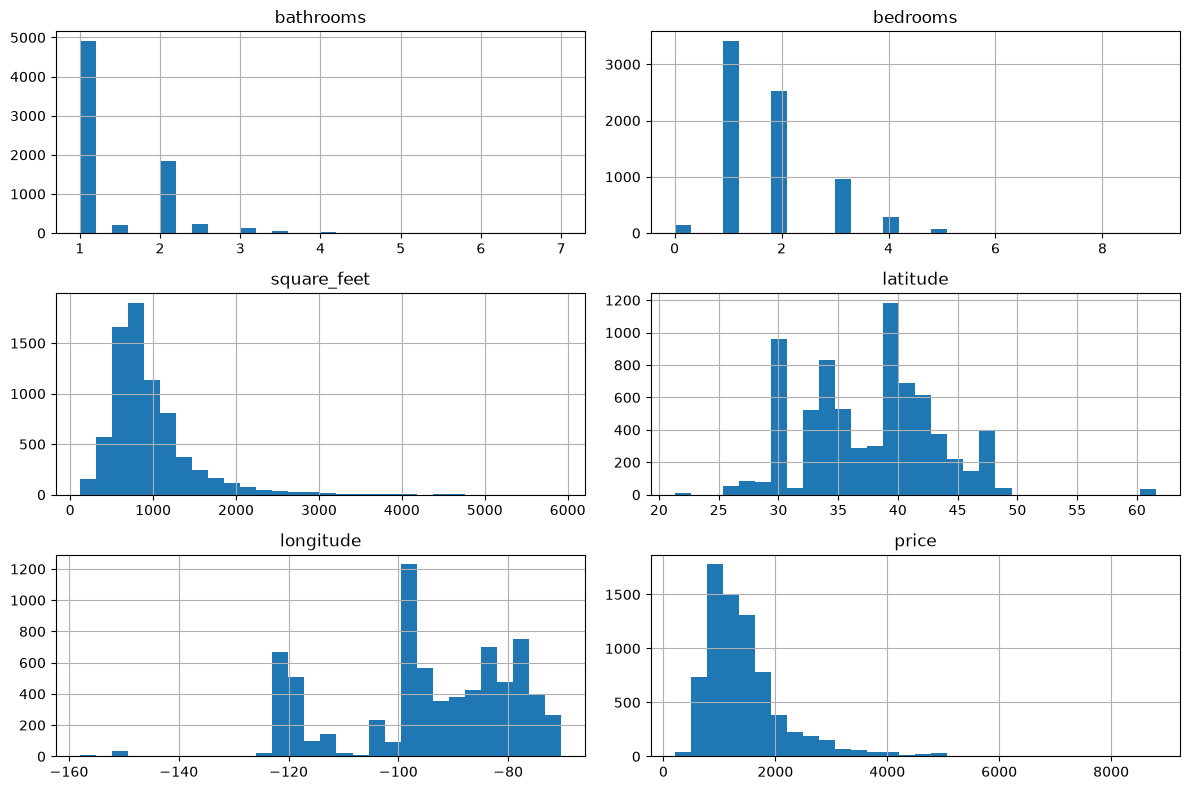

In [129]:

import matplotlib.pyplot as plt

train_df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

In [130]:

numeric_cols = [
    "bathrooms", "bedrooms", "square_feet",
    "latitude", "longitude", "price"
]

total_rows = len(train_df)

for col in numeric_cols:
    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (train_df[col] < lower_bound) |
        (train_df[col] > upper_bound)
    )

    count = outliers.sum()
    percentage = count / total_rows * 100

    print(f"\n{col}")
    print(f"Outlier count: {count}")
    print(f"Percentage of dataset: {percentage:.2f}%")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")


bathrooms
Outlier count: 48
Percentage of dataset: 0.65%
Lower bound: -0.50
Upper bound: 3.50

bedrooms
Outlier count: 370
Percentage of dataset: 5.00%
Lower bound: -0.50
Upper bound: 3.50

square_feet
Outlier count: 455
Percentage of dataset: 6.15%
Lower bound: -25.00
Upper bound: 1775.00

latitude
Outlier count: 44
Percentage of dataset: 0.59%
Lower bound: 21.99
Upper bound: 52.97

longitude
Outlier count: 44
Percentage of dataset: 0.59%
Lower bound: -123.86
Upper bound: -56.32

price
Outlier count: 443
Percentage of dataset: 5.99%
Lower bound: -170.00
Upper bound: 2814.00


##### Outlier Detection summary

I used the Interquartile Range (IQR) method with a multiplier of 1.5 to identify potential outliers in the numerical features. The largest percentages of flagged observations occurred in `square_feet` (6.15%), `price` (5.99%), and `bedrooms` (5.00%). Outliers were also identified in `bathrooms`, `latitude`, and `longitude`.

After reviewing the summary statistics, I decided to retain the observations because extreme values may represent legitimate rental listings rather than data errors. No rows were removed solely based on the IQR method.
